# Catálogo JPL: ¿funciona el modelo con asteroides recién descubiertos?

**Introducción a la Inteligencia Artificial** · 6.º semestre · complemento de `pipeline_asteroides.ipynb`

**Integrantes:** Dylan Alexander Mejia Ceballos · Luis Miguel Brito Rincon · Gabriel Alejandro Giraldo Ayerbe · Juan Pablo Muñoz Corchos · Juan Pablo Agudelo · Evelyn Gómez Aristizabal

En el notebook principal vimos que, si el modelo tiene el MOID, solo copia la regla de la NASA. Aquí probamos un uso más realista: **entrenar con los asteroides descubiertos hasta 2023 y evaluar con los descubiertos de 2024 en adelante**, como si el modelo ya estuviera funcionando y le llegaran objetos nuevos. Muchos de ellos tienen pocas observaciones y una órbita todavía incierta.

Los datos son el catálogo de objetos cercanos a la Tierra (NEOs) de la *Small-Body Database* (SBDB) del JPL de la NASA, descargado de su API oficial, con una fila por asteroide.

| | `nasa.csv` (notebook principal) | Catálogo JPL (este notebook) |
| :--- | :--- | :--- |
| Asteroides | 3,692 (4,687 filas) | ~42,900 |
| Filas repetidas por asteroide | Sí, por eso la partición es agrupada | No, una fila por asteroide |
| Actualidad | Versión antigua publicada en Kaggle | Descargado de la API oficial |
| Calidad de la órbita | `Orbit Uncertainity` | `condition_code`, `data_arc`, `n_obs_used` |
| Fecha de descubrimiento | No | `first_obs`, que permite partir por fecha |

## Contenido

0. [Configuración del entorno](#j0)
1. [Obtención de los datos](#j1)
2. [Cómo cambia el catálogo con el tiempo](#j2) · *Analyze*
3. [Partición temporal, variables y escenarios](#j3) · *Design*
4. [Comparación de modelos](#j4) · *Configure & Build*
5. [Evaluación con asteroides recién descubiertos](#j5) · *Configure & Build*
6. [Desempeño según la calidad de la órbita](#j6)
7. [Drift entre asteroides viejos y nuevos](#j7) · *Operate & Optimize*
8. [Resultados y conclusiones](#j8)
   - [8.1 Cifras clave](#j8-1)
   - [8.2 Datos para la presentación](#j8-2)
   - [8.3 Conclusiones](#j8-3)

<a id="j0"></a>
## 0. Configuración del entorno

Librerías, semilla y las mismas funciones auxiliares del notebook principal: el pipeline con imputación, el resumen de la validación cruzada, el umbral F2 y las métricas con un umbral dado.

In [1]:
# 0. Configuración del entorno y funciones auxiliares
import os

# Evita el error de joblib/loky con `wmic` en Windows 11 (igual que en el notebook principal)
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(max(1, (os.cpu_count() or 2) // 2)))

import json
import urllib.parse
import urllib.request
import warnings
from datetime import datetime
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.base import BaseEstimator, clone
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score, fbeta_score, make_scorer, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.max_colwidth', None)

SEED = 42
TARGET = 'peligroso'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)

SCORING: dict[str, Any] = {
    'pr_auc': 'average_precision',
    'f2': make_scorer(fbeta_score, beta=2),
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': make_scorer(precision_score, zero_division=0)
}


def hacer_pipeline(clf: BaseEstimator, escalador: Any = None) -> Pipeline:
    """Pipeline con imputación por mediana, escalado opcional y clasificador."""
    pasos: list[tuple[str, Any]] = [('imputer', SimpleImputer(strategy='median'))]
    if escalador is not None:
        pasos.append(('scaler', clone(escalador)))
    pasos.append(('clf', clf))
    return Pipeline(pasos)


def resumir_cv(res: dict[str, np.ndarray], metricas: list[str]) -> dict[str, float]:
    """Medias y desviaciones estándar de la salida de cross_validate."""
    out: dict[str, float] = {}
    for m in metricas:
        out[m] = float(np.mean(res[f'test_{m}']))
        out[f'{m}_std'] = float(np.std(res[f'test_{m}']))
    return out


def umbral_f2(y_true: np.ndarray, probs: np.ndarray) -> tuple[float, float]:
    """Umbral que maximiza F2 sobre la curva Precision-Recall, y el F2 alcanzado."""
    precs, recs, thrs = precision_recall_curve(y_true, probs)
    p, r = precs[:-1], recs[:-1]
    f2 = np.where((4 * p + r) > 0, 5 * p * r / (4 * p + r + 1e-12), 0)
    i = int(np.argmax(f2))
    return float(thrs[i]), float(f2[i])


def metricas_binarias(y_true: np.ndarray, probs: np.ndarray, umbral: float) -> dict[str, float]:
    """Métricas con un umbral dado. Las que no están definidas (p. ej. sin positivos) se devuelven como NaN."""
    y_true = np.asarray(y_true)
    pred = (np.asarray(probs) >= umbral).astype(int)
    dos_clases = len(np.unique(y_true)) == 2
    positivos = int(y_true.sum())
    return {
        'pr_auc': average_precision_score(y_true, probs) if dos_clases else np.nan,
        'roc_auc': roc_auc_score(y_true, probs) if dos_clases else np.nan,
        'f2': fbeta_score(y_true, pred, beta=2, zero_division=0) if positivos else np.nan,
        'f1': f1_score(y_true, pred, zero_division=0) if positivos else np.nan,
        'recall': recall_score(y_true, pred, zero_division=0) if positivos else np.nan,
        'precision': precision_score(y_true, pred, zero_division=0) if pred.sum() else np.nan,
        'accuracy': accuracy_score(y_true, pred),
        'positivos': positivos,
        'falsos_negativos': int(((pred == 0) & (y_true == 1)).sum()),
        'falsos_positivos': int(((pred == 1) & (y_true == 0)).sum())
    }


print(f'scikit-learn {sklearn.__version__} | pandas {pd.__version__}')

scikit-learn 1.6.1 | pandas 2.2.3


<a id="j1"></a>
## 1. Obtención de los datos (SBDB Query API)

Hacemos una sola consulta a `https://ssd-api.jpl.nasa.gov/sbdb_query.api` con `sb-group=neo` (todos los objetos cercanos a la Tierra) y guardamos el resultado en `sbdb_neos.csv`. Las siguientes ejecuciones leen ese archivo, así que el análisis se puede repetir sin internet y da los mismos resultados. Para actualizarlo basta con borrar el CSV o llamar `descargar_catalogo(..., forzar=True)`.

| Campo | Significado |
| :--- | :--- |
| `pha` | Etiqueta oficial: *Potentially Hazardous Asteroid* (Y/N) |
| `H` | Magnitud absoluta (menor = más grande) |
| `e`, `a`, `q`, `ad`, `i`, `om`, `w` | Excentricidad, semieje mayor, perihelio, afelio (UA), inclinación, nodo ascendente y argumento del perihelio (°) |
| `per`, `n`, `t_jup` | Período (días), movimiento medio (°/día) e invariante de Tisserand respecto a Júpiter |
| `moid` | Distancia mínima entre la órbita del asteroide y la de la Tierra (UA) |
| `condition_code` | Calidad de la órbita: 0 = muy bien determinada, 9 = muy incierta |
| `data_arc`, `n_obs_used` | Días entre la primera y la última observación, y número de observaciones usadas |
| `first_obs` | Fecha de la primera observación (más o menos, la del descubrimiento) |

In [2]:
# 1. Descarga (o lectura del CSV guardado) y limpieza
RUTA_CATALOGO = Path('sbdb_neos.csv')
URL_API = 'https://ssd-api.jpl.nasa.gov/sbdb_query.api'
CAMPOS = ['spkid', 'pdes', 'full_name', 'pha', 'H', 'diameter', 'albedo', 'e', 'a', 'q', 'i', 'om', 'w', 'ma',
          'ad', 'per', 'n', 'moid', 't_jup', 'condition_code', 'data_arc', 'n_obs_used', 'first_obs', 'last_obs', 'class']
NUMERICAS = ['H', 'diameter', 'albedo', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'per', 'n', 'moid', 't_jup',
             'condition_code', 'data_arc', 'n_obs_used']


def descargar_catalogo(ruta: Path, forzar: bool = False) -> pd.DataFrame:
    """Descarga el catálogo de NEOs de la SBDB en una sola consulta y lo guarda como CSV; si ya existe, lo reutiliza."""
    if ruta.exists() and not forzar:
        return pd.read_csv(ruta, dtype={'spkid': str, 'pdes': str})
    url = URL_API + '?' + urllib.parse.urlencode({'fields': ','.join(CAMPOS), 'sb-group': 'neo'})
    with urllib.request.urlopen(url, timeout=180) as resp:
        payload = json.load(resp)
    cat = pd.DataFrame(payload['data'], columns=payload['fields'])
    cat.to_csv(ruta, index=False)
    return pd.read_csv(ruta, dtype={'spkid': str, 'pdes': str})


bruto = descargar_catalogo(RUTA_CATALOGO)
FECHA_CATALOGO = datetime.fromtimestamp(RUTA_CATALOGO.stat().st_mtime).date().isoformat()
print(f'Catálogo: {len(bruto):,} NEOs | descargado el {FECHA_CATALOGO} | {RUTA_CATALOGO.stat().st_size / 1e6:.1f} MB')

cat = bruto.copy()
cat[NUMERICAS] = cat[NUMERICAS].apply(pd.to_numeric, errors='coerce')
cat['anio'] = pd.to_datetime(cat['first_obs'], errors='coerce').dt.year
assert cat['pdes'].is_unique, 'Hay asteroides repetidos'

sin_etiqueta = cat['pha'].isna() | cat['anio'].isna()
print(f'Descartados {sin_etiqueta.sum()} objetos sin etiqueta PHA o sin fecha de descubrimiento '
      f'(sin H, la NASA no puede clasificarlos).')
cat = cat[~sin_etiqueta].copy()
cat['anio'] = cat['anio'].astype(int)
cat[TARGET] = (cat['pha'] == 'Y').astype(int)

print(f'Asteroides válidos: {len(cat):,} | peligrosos (PHA): {cat[TARGET].sum():,} ({cat[TARGET].mean():.1%})')
print('Valores faltantes por variable:', (cat[NUMERICAS].isna().mean() * 100).round(1).loc[lambda s: s > 0].to_dict())

# La etiqueta sigue siendo la regla CNEOS, igual que en nasa.csv
regla = ((cat['moid'] <= 0.05) & (cat['H'] <= 22.0)).astype(int)
ACUERDO_REGLA = float((regla == cat[TARGET]).mean())
print(f'Coincidencia de la regla (MOID <= 0.05 y H <= 22) con la etiqueta oficial: {ACUERDO_REGLA:.2%}')
display(pd.crosstab(regla.rename('Regla'), cat[TARGET].rename('PHA oficial')))

Catálogo: 42,926 NEOs | descargado el 2026-10-11 | 6.7 MB
Descartados 344 objetos sin etiqueta PHA o sin fecha de descubrimiento (sin H, la NASA no puede clasificarlos).
Asteroides válidos: 42,582 | peligrosos (PHA): 2,550 (6.0%)
Valores faltantes por variable: {'diameter': 97.1, 'albedo': 97.2, 'data_arc': 1.0}
Coincidencia de la regla (MOID <= 0.05 y H <= 22) con la etiqueta oficial: 99.88%


PHA oficial,0,1
Regla,,
0,40015,33
1,17,2517


<a id="j2"></a>
## 2. Cómo cambia el catálogo con el tiempo (Analyze)

Antes de modelar hay que ver qué tipo de asteroides se están descubriendo ahora. Los telescopios son cada vez más sensibles y detectan objetos más pequeños (con H mayor). Como la regla exige $H \le 22$, esperamos que entre los recién descubiertos haya menos peligrosos que en el histórico. Ese cambio en los datos (*drift*) es algo que el modelo tiene que aguantar.

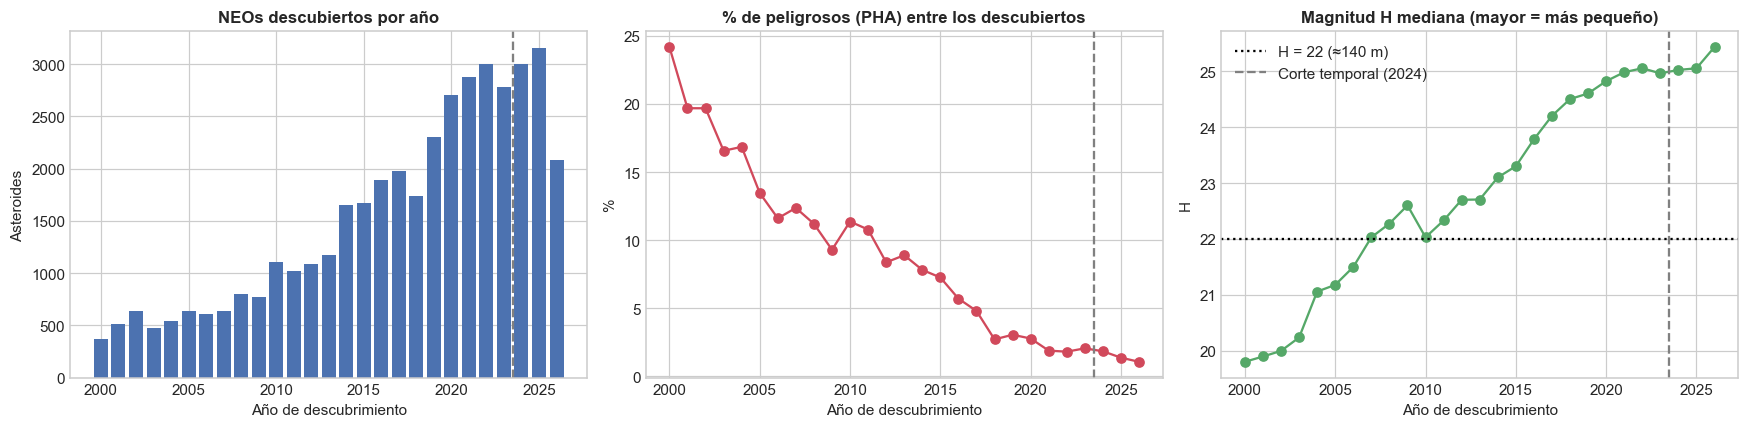

Nota: 2026 es un año incompleto (catálogo descargado el 2026-10-11).


,asteroides,pct_pha,pct_H_menor_22,H_mediana,arco_mediano_dias,obs_medianas
periodo,,,,,,
Histórico (< 2024),34340,0.071,0.319,23.745,28.0,46.0
Recientes (2024-2026),8242,0.015,0.096,25.130,10.0,34.0


Distribución de la calidad de órbita por periodo (% de asteroides):


calidad_orbita,Buena (U 0-3),Media (U 4-6),Incierta (U 7-9)
periodo,,,
Histórico (< 2024),32.9,18.8,48.2
Recientes (2024-2026),1.9,29.5,68.6


In [3]:
# 2. Evolución de los descubrimientos por año
ANIO_CORTE = 2024   # Train/Val: descubiertos hasta 2023 | Test: descubiertos en 2024 o después
ANIO_ACTUAL = int(cat['anio'].max())

por_anio = cat.groupby('anio').agg(descubiertos=(TARGET, 'size'), pct_pha=(TARGET, 'mean'), H_mediana=('H', 'median'),
                                   pct_grandes=('H', lambda h: (h <= 22).mean()))
sub = por_anio.loc[2000:]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(sub.index, sub['descubiertos'], color='#4C72B0')
axes[0].set_title('NEOs descubiertos por año')
axes[0].set_ylabel('Asteroides')
axes[1].plot(sub.index, 100 * sub['pct_pha'], marker='o', color='#D1495B')
axes[1].set_title('% de peligrosos (PHA) entre los descubiertos')
axes[1].set_ylabel('%')
axes[2].plot(sub.index, sub['H_mediana'], marker='o', color='#55A868')
axes[2].axhline(22, color='black', ls=':', label='H = 22 (≈140 m)')
axes[2].set_title('Magnitud H mediana (mayor = más pequeño)')
axes[2].set_ylabel('H')
for ax in axes:
    ax.axvline(ANIO_CORTE - 0.5, color='gray', ls='--', label=f'Corte temporal ({ANIO_CORTE})')
    ax.set_xlabel('Año de descubrimiento')
axes[2].legend()
plt.tight_layout()
plt.show()
print(f'Nota: {ANIO_ACTUAL} es un año incompleto (catálogo descargado el {FECHA_CATALOGO}).')

# Comparación histórico vs recientes
cat['periodo'] = np.where(cat['anio'] < ANIO_CORTE, f'Histórico (< {ANIO_CORTE})', f'Recientes ({ANIO_CORTE}-{ANIO_ACTUAL})')
cat['calidad_orbita'] = pd.cut(cat['condition_code'], [-1, 3, 6, 9],
                               labels=['Buena (U 0-3)', 'Media (U 4-6)', 'Incierta (U 7-9)'])
resumen_periodo = cat.groupby('periodo').agg(
    asteroides=(TARGET, 'size'), pct_pha=(TARGET, 'mean'), pct_H_menor_22=('H', lambda h: (h <= 22).mean()),
    H_mediana=('H', 'median'), arco_mediano_dias=('data_arc', 'median'), obs_medianas=('n_obs_used', 'median'))
display(resumen_periodo.round(3))
print('Distribución de la calidad de órbita por periodo (% de asteroides):')
display((pd.crosstab(cat['periodo'], cat['calidad_orbita'], normalize='index') * 100).round(1))

<a id="j3"></a>
## 3. Partición temporal, variables y escenarios (Design)

**Partición por fecha de descubrimiento (simula el uso real):**

- **Train (80%) y Validación (20%):** asteroides descubiertos antes de 2024, partidos al azar de forma estratificada. Validación solo se usa para escoger el umbral F2.
- **Test:** todos los asteroides descubiertos de 2024 en adelante. El modelo nunca los vio y llegaron después, como pasaría en la práctica.

Aquí hay una fila por asteroide, así que no existe la fuga por agrupamiento del notebook principal y basta con `StratifiedKFold`.

**Variables que no usamos:**

- `diameter` y `albedo`: faltan en ~97% de los asteroides (solo se conocen para los que se han estudiado a fondo). El tamaño ya está en `H`.
- `ma` (anomalía media): dice en qué punto de su órbita va el asteroide en una fecha cualquiera; no cambia el riesgo.
- `condition_code`, `data_arc`, `n_obs_used` y las fechas: dicen cuánto se ha observado el asteroide, no cómo es. Las usamos para analizar los resultados ([sección 6](#j6)), no para predecir, para que el modelo no aprenda atajos como "objeto viejo y muy observado".

**Escenarios** (los mismos del notebook principal):

- **A:** todas las variables, incluido `moid`. El modelo puede copiar la regla.
- **B:** sin `moid`. El modelo tiene que deducir la cercanía a partir de la órbita. Es el escenario que más nos interesa.
- **C:** sin `moid` ni `H`. Sin ninguna de las dos condiciones de la definición.

In [4]:
# 3. Variables, escenarios y partición temporal
FEATURES = ['H', 'e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup', 'moid']
ESCENARIOS: dict[str, list[str]] = {
    'A_completo': [],
    'B_sin_MOID': ['moid'],
    'C_sin_definicion': ['moid', 'H']
}
ESCENARIO_FOCO = 'B_sin_MOID'


def columnas_escenario(nombre: str) -> list[str]:
    """Variables predictoras disponibles en un escenario de fuga."""
    return [c for c in FEATURES if c not in ESCENARIOS[nombre]]


historico = cat[cat['anio'] < ANIO_CORTE]
test = cat[cat['anio'] >= ANIO_CORTE].copy()
train, val = train_test_split(historico, test_size=0.2, stratify=historico[TARGET], random_state=SEED)
y_train, y_val, y_test = train[TARGET].to_numpy(), val[TARGET].to_numpy(), test[TARGET].to_numpy()

assert not (set(train['pdes']) & set(test['pdes'])) and not (set(val['pdes']) & set(test['pdes']))
print('Partición temporal:')
for nombre, d in [('Train', train), ('Validación', val), (f'Test ({ANIO_CORTE}-{ANIO_ACTUAL})', test)]:
    print(f'{nombre:18s}: {len(d):6,} asteroides | {d[TARGET].sum():5,} PHA ({d[TARGET].mean():5.2%}) | '
          f'H mediana {d["H"].median():.1f} | órbita incierta (U 7-9): {(d["condition_code"] >= 7).mean():.0%}')
for esc in ESCENARIOS:
    print(f'  · {esc:17s}: {columnas_escenario(esc)}')

Partición temporal:
Train             : 27,472 asteroides | 1,944 PHA (7.08%) | H mediana 23.7 | órbita incierta (U 7-9): 48%
Validación        :  6,868 asteroides |   486 PHA (7.08%) | H mediana 23.8 | órbita incierta (U 7-9): 48%
Test (2024-2026)  :  8,242 asteroides |   120 PHA (1.46%) | H mediana 25.1 | órbita incierta (U 7-9): 69%
  · A_completo       : ['H', 'e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup', 'moid']
  · B_sin_MOID       : ['H', 'e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup']
  · C_sin_definicion : ['e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup']


<a id="j4"></a>
## 4. Comparación de modelos (Configure & Build)

Validación cruzada de 5 folds sobre Train. Probamos los modelos que mejor funcionaron en el notebook principal y dos de referencia; SVM, k-NN y MLP los dejamos por fuera porque son lentos con ~30,000 filas y allá no se destacaron.

- `Baseline` (clase mayoritaria) y `Regresión logística` (referencia lineal).
- `Random Forest`, `Bagging` (con la configuración que ganó en el notebook principal: 200 árboles, `max_features=0.7`) y `Gradient Boosting`.

Ordenamos por PR-AUC, que es la métrica adecuada porque aquí solo ~6% son peligrosos, y si hay empate, por F2.

In [5]:
# 4. Comparación de modelos por escenario
MODELOS: dict[str, Pipeline] = {
    'Baseline (Mayoritaria)': hacer_pipeline(DummyClassifier(strategy='most_frequent')),
    'Regresión Logística': hacer_pipeline(LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED),
                                          StandardScaler()),
    'Random Forest': hacer_pipeline(RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=1)),
    'Bagging': hacer_pipeline(BaggingClassifier(n_estimators=200, max_features=0.7, random_state=SEED, n_jobs=1)),
    'Gradient Boosting': hacer_pipeline(GradientBoostingClassifier(random_state=SEED))
}
METRICAS = list(SCORING)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

filas = []
for esc in ESCENARIOS:
    X_tr = train[columnas_escenario(esc)]
    for nombre, modelo in MODELOS.items():
        res = cross_validate(clone(modelo), X_tr, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
        filas.append({'Escenario': esc, 'Modelo': nombre, **resumir_cv(res, METRICAS)})
df_bench = pd.DataFrame(filas)

rankings: dict[str, pd.DataFrame] = {
    esc: (df_bench[df_bench['Escenario'] == esc].sort_values(['pr_auc', 'f2'], ascending=False).reset_index(drop=True))
    for esc in ESCENARIOS
}
for esc, r in rankings.items():
    tabla = r[['Modelo']].copy()
    for m in METRICAS:
        tabla[m] = r[m].map('{:.4f}'.format) + ' ± ' + r[f'{m}_std'].map('{:.4f}'.format)
    print(f'\nRanking CV 5-fold: {esc}')
    display(tabla)

pivot_pr = df_bench.pivot(index='Modelo', columns='Escenario', values='pr_auc')[list(ESCENARIOS)]
print('PR-AUC por escenario (CV):')
display(pivot_pr.sort_values('B_sin_MOID', ascending=False).round(4))


Ranking CV 5-fold: A_completo


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision
0,Random Forest,0.9961 ± 0.0022,0.9905 ± 0.0038,0.9902 ± 0.0042,0.9989 ± 0.0008,0.9907 ± 0.0045,0.9898 ± 0.0075
1,Gradient Boosting,0.9960 ± 0.0054,0.9886 ± 0.0035,0.9899 ± 0.0025,0.9998 ± 0.0001,0.9877 ± 0.0044,0.9923 ± 0.0032
2,Bagging,0.9944 ± 0.0040,0.9819 ± 0.0051,0.9865 ± 0.0034,0.9991 ± 0.0003,0.9789 ± 0.0064,0.9943 ± 0.0035
3,Regresión Logística,0.8381 ± 0.0247,0.8410 ± 0.0087,0.7048 ± 0.0091,0.9879 ± 0.0018,0.9655 ± 0.0104,0.5550 ± 0.0098
4,Baseline (Mayoritaria),0.0708 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000



Ranking CV 5-fold: B_sin_MOID


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision
0,Bagging,0.8091 ± 0.0125,0.2594 ± 0.0051,0.3542 ± 0.0067,0.9833 ± 0.0015,0.2202 ± 0.0044,0.9049 ± 0.0173
1,Gradient Boosting,0.7562 ± 0.0194,0.4871 ± 0.0205,0.5690 ± 0.0199,0.9765 ± 0.0018,0.4445 ± 0.0208,0.7920 ± 0.0297
2,Random Forest,0.7437 ± 0.0091,0.4888 ± 0.0205,0.5664 ± 0.0146,0.9768 ± 0.0014,0.4480 ± 0.0228,0.7720 ± 0.0181
3,Regresión Logística,0.2793 ± 0.0150,0.6042 ± 0.0066,0.4081 ± 0.0056,0.8986 ± 0.0045,0.8889 ± 0.0113,0.2649 ± 0.0045
4,Baseline (Mayoritaria),0.0708 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000



Ranking CV 5-fold: C_sin_definicion


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision
0,Gradient Boosting,0.1984 ± 0.0084,0.0045 ± 0.0043,0.0071 ± 0.0068,0.7904 ± 0.0073,0.0036 ± 0.0035,0.2300 ± 0.1392
1,Bagging,0.1978 ± 0.0083,0.0096 ± 0.0053,0.0151 ± 0.0084,0.7861 ± 0.0074,0.0077 ± 0.0043,0.3177 ± 0.1990
2,Random Forest,0.1834 ± 0.0086,0.0083 ± 0.0048,0.0130 ± 0.0075,0.7811 ± 0.0075,0.0067 ± 0.0038,0.2525 ± 0.1539
3,Regresión Logística,0.1519 ± 0.0056,0.3918 ± 0.0126,0.2481 ± 0.0063,0.7573 ± 0.0070,0.6389 ± 0.0297,0.1539 ± 0.0035
4,Baseline (Mayoritaria),0.0708 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000


PR-AUC por escenario (CV):


Escenario,A_completo,B_sin_MOID,C_sin_definicion
Modelo,,,
Bagging,0.9944,0.8091,0.1978
Gradient Boosting,0.9960,0.7562,0.1984
Random Forest,0.9961,0.7437,0.1834
Regresión Logística,0.8381,0.2793,0.1519
Baseline (Mayoritaria),0.0708,0.0708,0.0708


<a id="j5"></a>
## 5. Evaluación con asteroides recién descubiertos (Test 2024 en adelante)

En cada escenario el ganador se entrena con Train, el umbral se escoge en Validación maximizando F2 y se evalúa una sola vez en Test.

Validación tiene asteroides del mismo periodo que Train y Test tiene asteroides posteriores. Comparar los dos muestra cuánto se degrada el modelo cuando la población cambia con el tiempo.

,Modelo,Umbral F2,Val PR-AUC,Test PR-AUC,Val Recall,Test Recall,Val Precision,Test Precision,Val F2,Test F2,Test PHA detectados,Test falsas alarmas,Test Recall (umbral 0.5)
Escenario,,,,,,,,,,,,,
A_completo,Random Forest,0.165,0.9984,0.9976,0.9959,1.0000,0.9699,0.9023,0.9906,0.9788,120 de 120,13,0.9917
B_sin_MOID,Bagging,0.220,0.8650,0.7843,0.9671,0.9917,0.5942,0.4146,0.8592,0.7757,119 de 120,168,0.2833
C_sin_definicion,Gradient Boosting,0.088,0.2241,0.0983,0.7325,0.8167,0.1668,0.0410,0.4365,0.1706,98 de 120,2295,0.0000


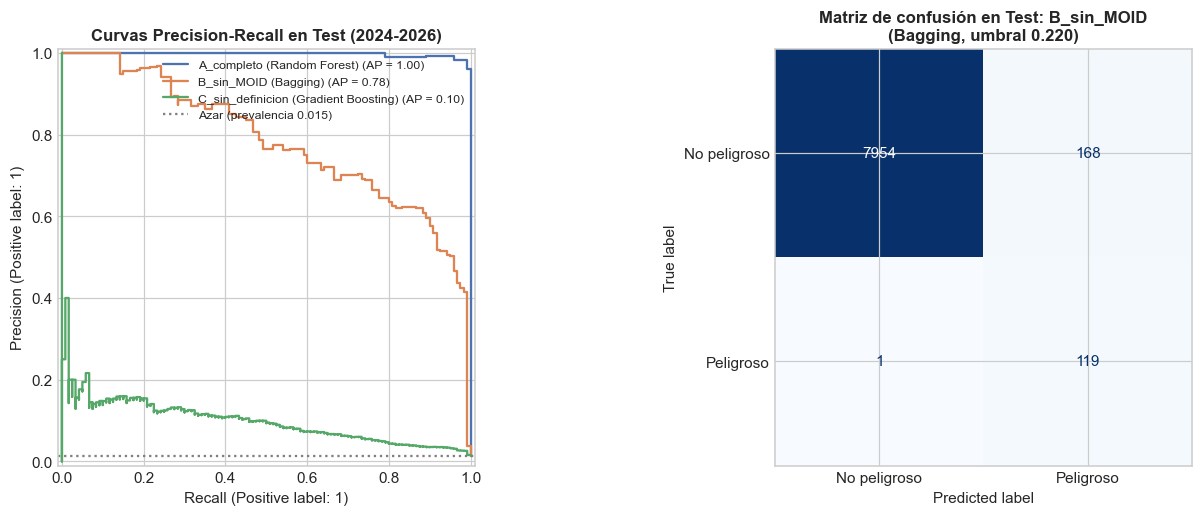

In [6]:
# 5. Ganador por escenario: entrenamiento, umbral en Validación y evaluación en Test
resultados: dict[str, dict[str, Any]] = {}
for esc in ESCENARIOS:
    ganador = rankings[esc].loc[rankings[esc]['Modelo'] != 'Baseline (Mayoritaria)', 'Modelo'].iloc[0]
    cols = columnas_escenario(esc)
    modelo = clone(MODELOS[ganador]).fit(train[cols], y_train)
    p_val = modelo.predict_proba(val[cols])[:, 1]
    umbral, _ = umbral_f2(y_val, p_val)
    p_test = modelo.predict_proba(test[cols])[:, 1]
    resultados[esc] = {
        'modelo_nombre': ganador, 'modelo': modelo, 'umbral': umbral, 'probs_val': p_val, 'probs_test': p_test,
        'val': metricas_binarias(y_val, p_val, umbral),
        'test': metricas_binarias(y_test, p_test, umbral),
        'test_umbral_05': metricas_binarias(y_test, p_test, 0.5)
    }

tabla_eval = pd.DataFrame([{
    'Escenario': esc, 'Modelo': r['modelo_nombre'], 'Umbral F2': round(r['umbral'], 3),
    'Val PR-AUC': r['val']['pr_auc'], 'Test PR-AUC': r['test']['pr_auc'],
    'Val Recall': r['val']['recall'], 'Test Recall': r['test']['recall'],
    'Val Precision': r['val']['precision'], 'Test Precision': r['test']['precision'],
    'Val F2': r['val']['f2'], 'Test F2': r['test']['f2'],
    'Test PHA detectados': f"{r['test']['positivos'] - r['test']['falsos_negativos']} de {r['test']['positivos']}",
    'Test falsas alarmas': r['test']['falsos_positivos'],
    'Test Recall (umbral 0.5)': r['test_umbral_05']['recall']
} for esc, r in resultados.items()]).set_index('Escenario')
display(tabla_eval.round(4))

# Curvas Precision-Recall en Test y matriz de confusión del escenario de interés
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colores = {'A_completo': '#4C72B0', 'B_sin_MOID': '#DD8452', 'C_sin_definicion': '#55A868'}
for esc, r in resultados.items():
    PrecisionRecallDisplay.from_predictions(y_test, r['probs_test'], name=f"{esc} ({r['modelo_nombre']})",
                                            ax=axes[0], color=colores[esc])
axes[0].axhline(y_test.mean(), color='gray', ls=':', label=f'Azar (prevalencia {y_test.mean():.3f})')
axes[0].set_title(f'Curvas Precision-Recall en Test ({ANIO_CORTE}-{ANIO_ACTUAL})')
axes[0].legend(fontsize=8, loc='upper right')
r_foco = resultados[ESCENARIO_FOCO]
ConfusionMatrixDisplay.from_predictions(y_test, (r_foco['probs_test'] >= r_foco['umbral']).astype(int),
                                        display_labels=['No peligroso', 'Peligroso'], cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title(f"Matriz de confusión en Test: {ESCENARIO_FOCO}\n({r_foco['modelo_nombre']}, umbral {r_foco['umbral']:.3f})")
plt.tight_layout()
plt.show()

<a id="j6"></a>
## 6. Desempeño según la calidad de la órbita

Dentro de Test separamos los asteroides según qué tan bien se conoce su órbita (`condition_code`) y cuántos días se han observado (`data_arc`). Un asteroide recién descubierto suele tener pocos días de observación y una órbita incierta (U 7–9).

Miramos el modelo del escenario B en dos grupos:

1. Todos los asteroides de Test.
2. Solo los grandes ($H \le 22$), que son los únicos que pueden ser peligrosos según la definición. Con los pequeños el modelo acierta fácil porque le basta mirar H; con los grandes está la parte difícil.


Por calidad de órbita: Todos los asteroides de Test


,Asteroides,PHA reales,% PHA,PHA detectados,Recall,Precision,F2,PR-AUC,Falsas alarmas
Grupo,,,,,,,,,
Todos,8242,120,0.015,119,0.992,0.415,0.776,0.784,168
Buena (U 0-3),156,17,0.109,17,1.000,0.607,0.885,0.792,11
Media (U 4-6),2432,63,0.026,62,0.984,0.437,0.787,0.792,80
Incierta (U 7-9),5653,40,0.007,40,1.000,0.342,0.722,0.801,77



Por calidad de órbita: Solo grandes (H <= 22)


,Asteroides,PHA reales,% PHA,PHA detectados,Recall,Precision,F2,PR-AUC,Falsas alarmas
Grupo,,,,,,,,,
Todos,792,120,0.152,119,0.992,0.431,0.787,0.789,157
Buena (U 0-3),54,17,0.315,17,1.000,0.607,0.885,0.792,11
Media (U 4-6),463,63,0.136,62,0.984,0.449,0.795,0.796,76
Incierta (U 7-9),274,40,0.146,40,1.000,0.364,0.741,0.804,70



Por días de observación: solo grandes (H <= 22)

,Asteroides,PHA reales,% PHA,PHA detectados,Recall,Precision,F2,PR-AUC,Falsas alarmas
Grupo,,,,,,,,,
Todos,792,120,0.152,119,0.992,0.431,0.787,0.789,157
< 30 días,260,37,0.142,37,1.000,0.370,0.746,0.781,63
30 días - 1 año,516,73,0.141,72,0.986,0.442,0.791,0.811,91
> 1 año,16,10,0.625,10,1.000,0.769,0.943,0.892,3


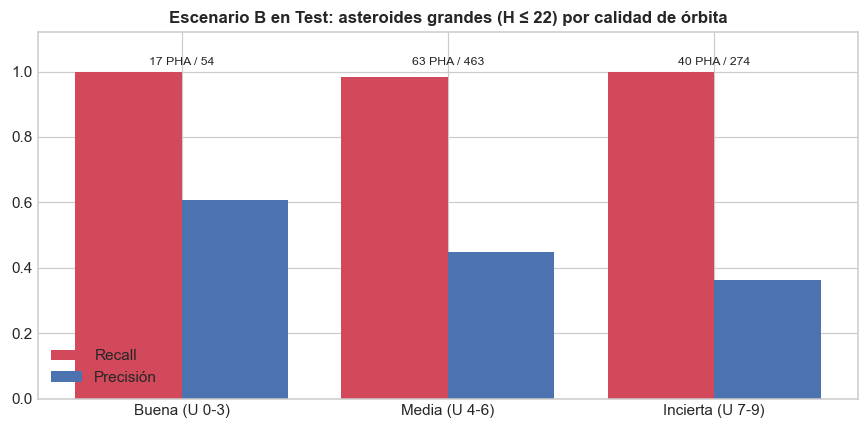

In [7]:
# 6. Desempeño del escenario B por calidad de órbita y por días de observación
test['prob_B'] = r_foco['probs_test']
test['arco'] = pd.cut(test['data_arc'], [-np.inf, 30, 365, np.inf],
                      labels=['< 30 días', '30 días - 1 año', '> 1 año'])


def tabla_por_grupo(datos: pd.DataFrame, columna: str, umbral: float) -> pd.DataFrame:
    """Métricas del modelo para todo el conjunto y para cada categoría de `columna`."""
    grupos = [('Todos', datos)] + [(str(k), g) for k, g in datos.groupby(columna, observed=True)]
    filas = []
    for nombre, g in grupos:
        m = metricas_binarias(g[TARGET].to_numpy(), g['prob_B'].to_numpy(), umbral)
        filas.append({'Grupo': nombre, 'Asteroides': len(g), 'PHA reales': m['positivos'],
                      '% PHA': g[TARGET].mean(), 'PHA detectados': m['positivos'] - m['falsos_negativos'],
                      'Recall': m['recall'], 'Precision': m['precision'], 'F2': m['f2'],
                      'PR-AUC': m['pr_auc'], 'Falsas alarmas': m['falsos_positivos']})
    return pd.DataFrame(filas).set_index('Grupo')


umbral_B = r_foco['umbral']
grandes = test[test['H'] <= 22]
tablas_calidad = {
    'Todos los asteroides de Test': tabla_por_grupo(test, 'calidad_orbita', umbral_B),
    'Solo grandes (H <= 22)': tabla_por_grupo(grandes, 'calidad_orbita', umbral_B)
}
for titulo, t in tablas_calidad.items():
    print(f'\nPor calidad de órbita: {titulo}')
    display(t.round(3))
tabla_arco = tabla_por_grupo(grandes, 'arco', umbral_B)
print('\nPor días de observación: solo grandes (H <= 22)')
display(tabla_arco.round(3))

# Recall y precisión por calidad de órbita (solo grandes)
t_plot = tablas_calidad['Solo grandes (H <= 22)'].drop(index='Todos')
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(t_plot))
ax.bar(x - 0.2, t_plot['Recall'], width=0.4, label='Recall', color='#D1495B')
ax.bar(x + 0.2, t_plot['Precision'], width=0.4, label='Precisión', color='#4C72B0')
for xi, (n_pha, n_tot) in enumerate(zip(t_plot['PHA reales'], t_plot['Asteroides'])):
    ax.text(xi, 1.02, f'{n_pha} PHA / {n_tot}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(t_plot.index)
ax.set_ylim(0, 1.12)
ax.set_title(f'Escenario B en Test: asteroides grandes (H ≤ 22) por calidad de órbita')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

<a id="j7"></a>
## 7. Drift entre asteroides viejos y nuevos (Operate & Optimize)

Usamos el mismo indicador del notebook principal, el PSI, para comparar la distribución de cada variable en Test con la de Train (menos de 0.1, estable; de 0.1 a 0.25, moderado; 0.25 o más, drift). Aquí el lote nuevo es real: son los asteroides descubiertos después del corte.

,PSI,Estado
H,0.4984,DRIFT
q,0.0350,Estable
t_jup,0.0154,Estable
e,0.0146,Estable
per,0.0141,Estable
a,0.0140,Estable
n,0.0138,Estable
ad,0.0135,Estable
i,0.0124,Estable
om,0.0106,Estable


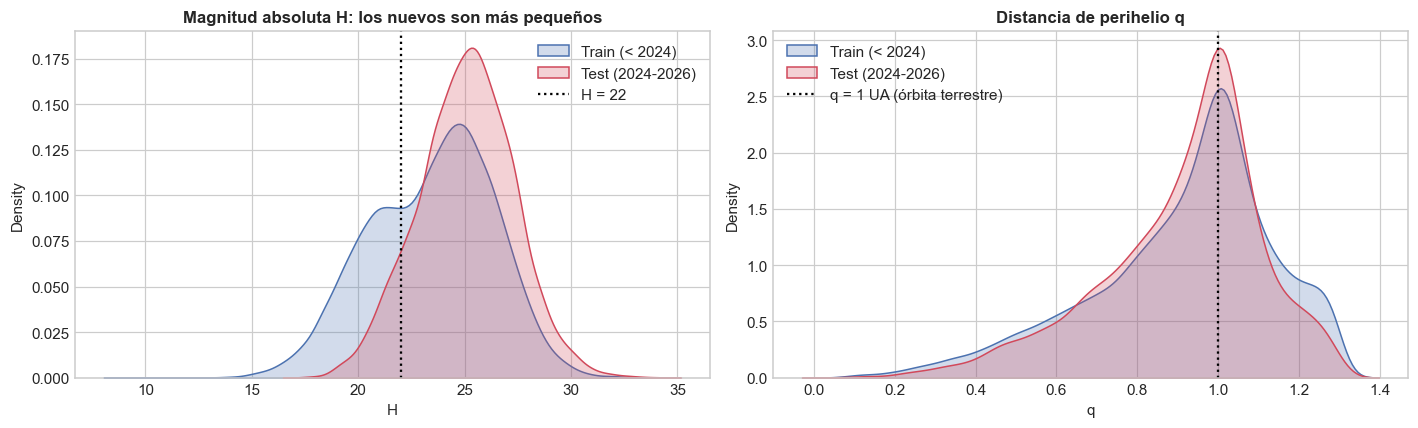

Tasa de alertas del modelo B: Validación 11.5% -> Test 3.5% (-8.0 pp). Prevalencia real: 7.1% -> 1.5%.


In [8]:
# 7. PSI por variable (Train como referencia, Test como lote nuevo)
def calcular_psi(referencia: np.ndarray, nuevos: np.ndarray, eps: float = 1e-4) -> float:
    """PSI con intervalos por deciles de la referencia (se usan las proporciones reales de cada intervalo)."""
    referencia = referencia[~np.isnan(referencia)]
    nuevos = nuevos[~np.isnan(nuevos)]
    bordes = np.unique(np.quantile(referencia, np.linspace(0, 1, 11)))
    bordes[0], bordes[-1] = -np.inf, np.inf
    p_ref = np.clip(np.histogram(referencia, bins=bordes)[0] / len(referencia), eps, None)
    p_new = np.clip(np.histogram(nuevos, bins=bordes)[0] / len(nuevos), eps, None)
    return float(np.sum((p_new - p_ref) * np.log(p_new / p_ref)))


df_psi = pd.DataFrame({'PSI': {c: calcular_psi(train[c].to_numpy(float), test[c].to_numpy(float))
                               for c in columnas_escenario(ESCENARIO_FOCO)}}).sort_values('PSI', ascending=False)
df_psi['Estado'] = pd.cut(df_psi['PSI'], [-np.inf, 0.1, 0.25, np.inf], labels=['Estable', 'Moderado', 'DRIFT'])
display(df_psi.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for d, etiqueta, color in [(train, f'Train (< {ANIO_CORTE})', '#4C72B0'), (test, f'Test ({ANIO_CORTE}-{ANIO_ACTUAL})', '#D1495B')]:
    sns.kdeplot(d['H'], ax=axes[0], label=etiqueta, color=color, fill=True, alpha=0.25)
    sns.kdeplot(d['q'], ax=axes[1], label=etiqueta, color=color, fill=True, alpha=0.25)
axes[0].axvline(22, color='black', ls=':', label='H = 22')
axes[0].set_title('Magnitud absoluta H: los nuevos son más pequeños')
axes[1].axvline(1.0, color='black', ls=':', label='q = 1 UA (órbita terrestre)')
axes[1].set_title('Distancia de perihelio q')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

tasa_ref = float((r_foco['probs_val'] >= umbral_B).mean())
tasa_test = float((r_foco['probs_test'] >= umbral_B).mean())
print(f'Tasa de alertas del modelo B: Validación {tasa_ref:.1%} -> Test {tasa_test:.1%} '
      f'({100 * (tasa_test - tasa_ref):+.1f} pp). Prevalencia real: {y_val.mean():.1%} -> {y_test.mean():.1%}.')

<a id="j8"></a>
## 8. Resultados y conclusiones

<a id="j8-1"></a>
### 8.1 Cifras clave

Las cifras de las conclusiones salen de esta tabla. También se guardan en `resultados/jpl_*`.

In [9]:
# 8.1 Cifras clave y exportación (resultados/jpl_*)
t_grandes = tablas_calidad['Solo grandes (H <= 22)']
resumen = {
    'Catálogo (fecha de descarga)': f'{len(cat):,} NEOs válidos ({FECHA_CATALOGO})',
    'Acuerdo regla CNEOS vs etiqueta': f'{ACUERDO_REGLA:.2%}',
    '% PHA: Train vs Test': f'{y_train.mean():.2%} vs {y_test.mean():.2%}',
    'H mediana: Train vs Test': f"{train['H'].median():.1f} vs {test['H'].median():.1f}",
    'Ganador A / B / C': ' / '.join(resultados[e]['modelo_nombre'] for e in ESCENARIOS),
    'PR-AUC Val -> Test (B)': f"{r_foco['val']['pr_auc']:.4f} -> {r_foco['test']['pr_auc']:.4f}",
    'Recall Val -> Test (B)': f"{r_foco['val']['recall']:.4f} -> {r_foco['test']['recall']:.4f}",
    'PHA detectados en Test (B)': f"{r_foco['test']['positivos'] - r_foco['test']['falsos_negativos']} de {r_foco['test']['positivos']}",
    'Falsas alarmas en Test (B)': f"{r_foco['test']['falsos_positivos']:,} de {int((y_test == 0).sum()):,} no peligrosos",
    'Recall grandes por calidad (Buena / Media / Incierta)': ' / '.join(
        f"{t_grandes.loc[g, 'Recall']:.3f}" if g in t_grandes.index else 'n/a'
        for g in ['Buena (U 0-3)', 'Media (U 4-6)', 'Incierta (U 7-9)']),
    'Variables con drift (PSI >= 0.25)': ', '.join(df_psi.index[df_psi['PSI'] >= 0.25]) or 'ninguna'
}
display(pd.Series(resumen, name='Valor').to_frame())

df_bench.to_csv(RESULTADOS / 'jpl_benchmark_cv.csv', index=False)
tabla_eval.to_csv(RESULTADOS / 'jpl_evaluacion_test.csv')
pd.concat(tablas_calidad, names=['Poblacion']).to_csv(RESULTADOS / 'jpl_test_por_calidad_orbita.csv')
(RESULTADOS / 'jpl_metrics_summary.json').write_text(json.dumps({
    'fecha_catalogo': FECHA_CATALOGO, 'anio_corte': ANIO_CORTE, 'resumen': resumen,
    'evaluacion': {esc: {k: r[k] for k in ['modelo_nombre', 'umbral', 'val', 'test', 'test_umbral_05']}
                   for esc, r in resultados.items()},
    'psi': df_psi['PSI'].to_dict()
}, indent=2, ensure_ascii=False, default=float), encoding='utf-8')
print('Exportado:', sorted(p.name for p in RESULTADOS.glob('jpl_*')))

,Valor
Catálogo (fecha de descarga),"42,582 NEOs válidos (2026-10-11)"
Acuerdo regla CNEOS vs etiqueta,99.88%
% PHA: Train vs Test,7.08% vs 1.46%
H mediana: Train vs Test,23.7 vs 25.1
Ganador A / B / C,Random Forest / Bagging / Gradient Boosting
PR-AUC Val -> Test (B),0.8650 -> 0.7843
Recall Val -> Test (B),0.9671 -> 0.9917
PHA detectados en Test (B),119 de 120
Falsas alarmas en Test (B),"168 de 8,122 no peligrosos"
Recall grandes por calidad (Buena / Media / Incierta),1.000 / 0.984 / 1.000


Exportado: ['jpl_benchmark_cv.csv', 'jpl_evaluacion_test.csv', 'jpl_metrics_summary.json', 'jpl_test_por_calidad_orbita.csv']


<a id="j8-2"></a>
### 8.2 Datos para la presentación

Exportamos a `resultados/presentacion_jpl.json` los datos de las gráficas de la presentación web, sin calcular nada nuevo.

In [10]:
# 8.2 Datos de las gráficas para la presentación web (carpeta presentacion/)
# Solo se exportan números ya calculados arriba: la presentación los dibuja, nunca los recalcula.
calidad_periodo = (pd.crosstab(cat['periodo'], cat['calidad_orbita'], normalize='index') * 100).round(1)
presentacion_jpl = {
    'catalogo': {'validos': int(len(cat)), 'pha': int(cat[TARGET].sum()), 'acuerdo_regla': ACUERDO_REGLA,
                 'fecha': FECHA_CATALOGO},
    'anio_corte': ANIO_CORTE, 'anio_actual': ANIO_ACTUAL,
    'por_anio': por_anio.loc[2000:].reset_index().round(4).to_dict(orient='records'),
    'periodos': resumen_periodo.reset_index().round(4).to_dict(orient='records'),
    'calidad_por_periodo': {str(p): {str(k): float(v) for k, v in fila.items()} for p, fila in calidad_periodo.iterrows()},
    'particion': {'train': int(len(train)), 'validacion': int(len(val)), 'test': int(len(test)),
                  'pha_train': int(y_train.sum()), 'pha_validacion': int(y_val.sum()), 'pha_test': int(y_test.sum())},
    'por_arco_grandes': tabla_arco.reset_index().round(4).to_dict(orient='records'),
    'alertas_b': {'tasa_validacion': tasa_ref, 'tasa_test': tasa_test},
}
(RESULTADOS / 'presentacion_jpl.json').write_text(
    json.dumps(presentacion_jpl, indent=1, ensure_ascii=False, default=float), encoding='utf-8')
print('Guardado resultados/presentacion_jpl.json:', ', '.join(presentacion_jpl))

Guardado resultados/presentacion_jpl.json: catalogo, anio_corte, anio_actual, por_anio, periodos, calidad_por_periodo, particion, por_arco_grandes, alertas_b


<a id="j8-3"></a>
### 8.3 Conclusiones

Cifras de la tabla de [8.1](#j8-1) (catálogo descargado el 2026-10-11, `SEED = 42`).

**1. Con el catálogo completo se confirma lo del notebook principal.** La etiqueta oficial coincide con la regla (MOID ≤ 0.05 y H ≤ 22) en el 99.88% de los 42,582 asteroides. Si el modelo tiene el MOID (escenario A), detecta los 120 de 120 peligrosos nuevos, pero no aprende nada: copia la regla.

**2. Los asteroides que se descubren hoy son distintos a los de antes.** Los telescopios actuales encuentran objetos más pequeños: la H mediana pasa de 23.7 (antes de 2024) a 25.1 (2024–2026). Por eso solo el 1.5% de los nuevos es peligroso, frente al 7.1% del histórico, y el 69% todavía tiene la órbita incierta (frente al 48%). El PSI de H es 0.50 (drift fuerte), mientras que las variables orbitales casi no cambian (PSI < 0.04).

**3. Sin el MOID (escenario B), el modelo sí funciona con asteroides del futuro.** Entrenado solo con asteroides descubiertos hasta 2023, el Bagging detectó **119 de los 120** peligrosos descubiertos en 2024–2026, con 168 falsas alarmas entre 8,122 no peligrosos. En la práctica: de 8,242 objetos nuevos, el modelo marca 287 (3.5%) para revisar, y en esa lista están casi todos los peligrosos. La precisión baja de 0.59 (Validación) a 0.41 (Test) porque entre los nuevos hay muchos menos peligrosos, no porque se le escapen más.

**4. Que la órbita sea incierta casi no le afecta.** Entre los asteroides grandes (H ≤ 22), el modelo detectó el 100%, el 98.4% y el 100% de los peligrosos con órbita buena, media e incierta, e incluso 37 de 37 de los observados menos de 30 días. Lo que sí sube con la incertidumbre son las falsas alarmas (precisión de 0.61 con órbita buena frente a 0.36 con órbita incierta). Ojo: la etiqueta de un asteroide con órbita incierta se calcula con esa misma órbita provisional, así que no sabemos cuántos dejarán de ser peligrosos (o pasarán a serlo) cuando su órbita se conozca mejor.

**5. El tamaño es indispensable.** Sin H (escenario C) el modelo se cae: PR-AUC de 0.098 en Test y 2,295 falsas alarmas para encontrar 98 peligrosos. Además empeora con el tiempo (PR-AUC de 0.224 en Validación y de 0.098 en Test), porque los nuevos son más pequeños y muchos tienen órbitas parecidas a las peligrosas aunque por tamaño no lo sean.

**6. El umbral vuelve a ser decisivo.** Con el umbral de 0.5, el modelo B solo detectaría 34 de 120 peligrosos (recall 0.28). Con el umbral escogido para F2 (0.22) detecta 119.

**¿Para qué sirve en la práctica?** La NASA calcula el MOID en cuanto un asteroide tiene órbita, así que este modelo no reemplaza ese cálculo. Lo que muestra es que un modelo sin MOID generaliza bien en el tiempo y con órbitas inciertas siempre que conozca el tamaño, y que podría servir como filtro para priorizar: reduce la lista de objetos por revisar al 3.5% sin perder casi ningún peligroso.

**Limitaciones**

1. Test tiene solo 120 peligrosos, así que una o dos detecciones de diferencia cambian el recall varios puntos.
2. Las etiquetas son una foto del catálogo de hoy; las órbitas provisionales van a cambiar.
3. 2026 es un año incompleto.
4. No ajustamos hiperparámetros: usamos la configuración que ganó en el notebook principal.